In [2]:
!pip install sidetable
!conda install -c conda-forge --yes scienceplots

Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done

# All requested packages already installed.



In [3]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [4]:
plt.style.use('science')

In [5]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [6]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [7]:
from simulation.helper.time import SimulationTimeConverter

In [8]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [9]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [34]:
auction_tracking

,time,timeslot,location,results.capacity,results.clearing_price,bids
0,0,30,872664c1effffff,0.0,0.000000,NaN
1,0,30,872664c1affffff,0.0,0.000000,NaN
2,0,30,87275934effffff,0.0,0.000000,NaN
3,0,30,872664cadffffff,0.0,0.000000,NaN
4,0,30,872664c16ffffff,0.0,0.000000,NaN
...,...,...,...,...,...,...
2227,1365,1395,872664cf5ffffff,0.0,0.000000,NaN
2228,1365,1395,872664cacffffff,0.0,0.000000,NaN
2229,1365,1395,872664c10ffffff,0.0,0.000000,NaN
2230,1365,1395,872664d89ffffff,0.0,0.000000,NaN


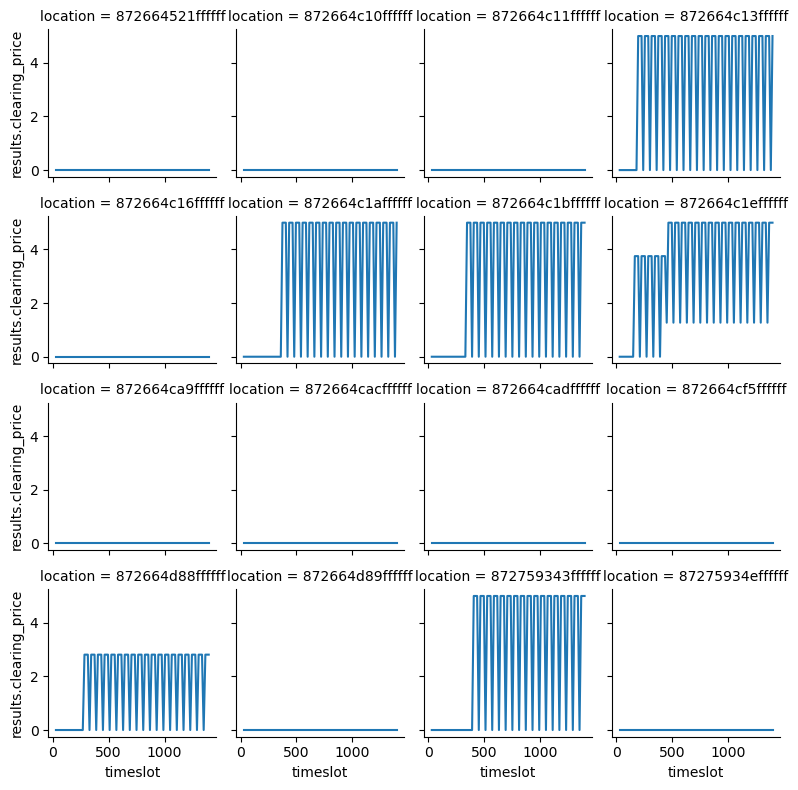

In [35]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
sns.relplot(data=auction_tracking, x="timeslot", y="results.clearing_price", col="location", col_wrap=4, kind="line", height=2)

In [39]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [40]:
vehicle_tracking['_state'].apply(lambda x: set(eval(x))).value_counts()

_state
{1, 2, 1003}                   868
{1, 2, 1003, 1001}             802
{1, 2, 3, 4, 5, 1003}          301
{1, 2, 3, 4, 5, 1001, 1003}    173
{1, 2, 3, 1003}                116
{1, 2, 3, 1001, 1003}          114
{1, 2, 1003, 4}                 97
{1, 2, 3, 4, 1003}              96
{1, 2, 4, 1001, 1003}           83
{1, 2, 3, 4, 1001, 1003}        59
{1, 2}                          51
{1, 2, 1001}                    40
{1, 2, 3, 4, 5}                 20
{1, 2, 3, 4}                    19
{1, 2, 3, 4, 1001}              11
{1, 2, 3, 4, 5, 1001}            9
{1}                              8
{1, 2, 3}                        4
{1, 2, 3, 1001}                  4
{1, 1001}                        2
{1, 1003}                        1
Name: count, dtype: int64

In [41]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per base region

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [42]:
# rename time axis
vehicle_tracking['time'] = pd.to_datetime(vehicle_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

vehicle_tracking['timestamp'] = vehicle_tracking['time'].dt.strftime("%H:%M")

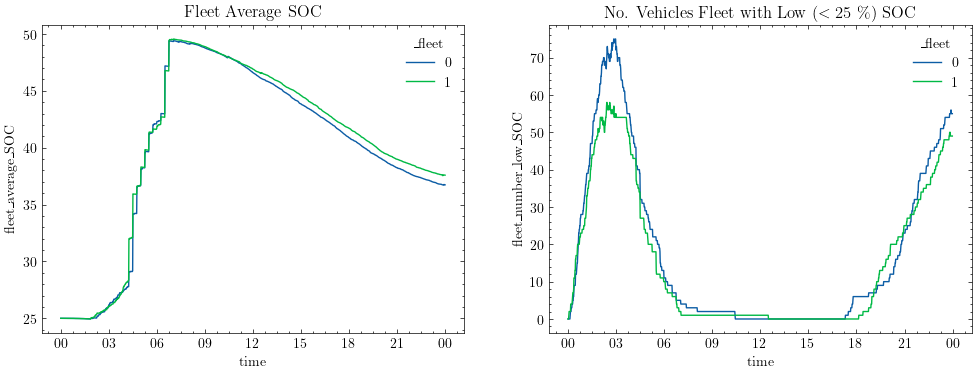

In [43]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [44]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [45]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking['_state_RELOCATING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking['_state_PRE_SERVICE'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking['_state_RESERVED'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

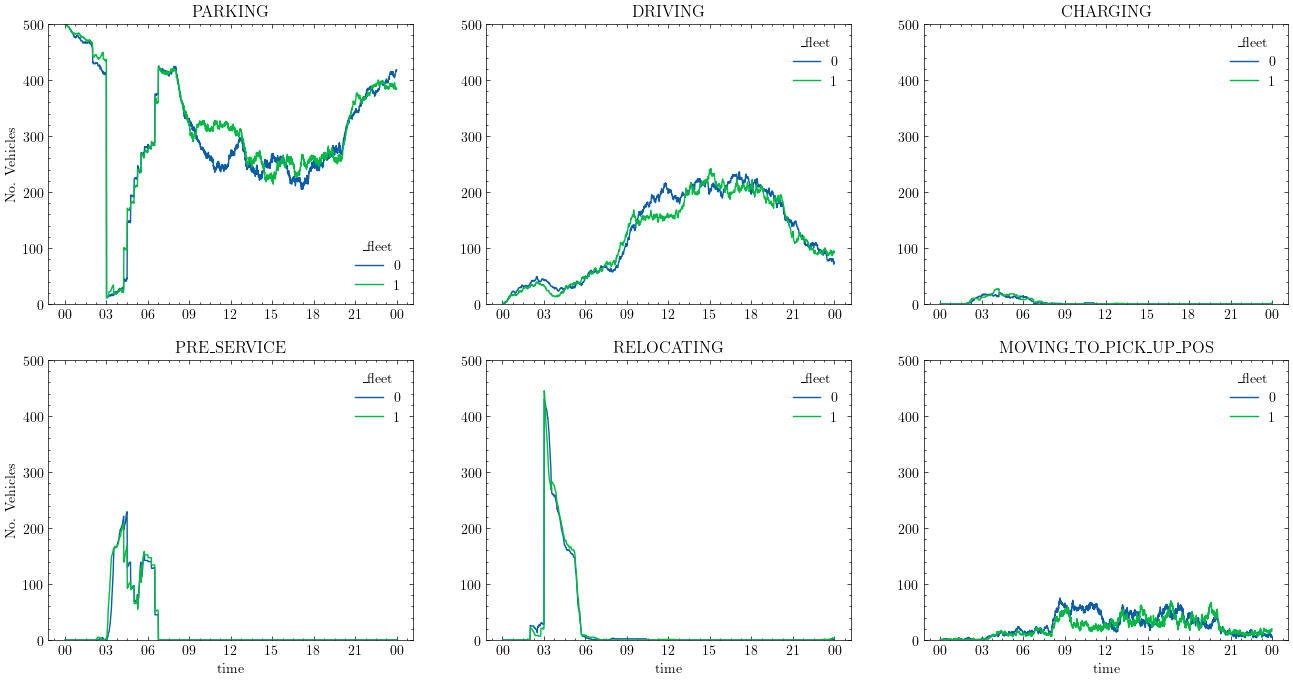

In [46]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

In [16]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [17]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [18]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

In [19]:
# rename time axis
charging_station_tracking['time'] = pd.to_datetime(charging_station_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

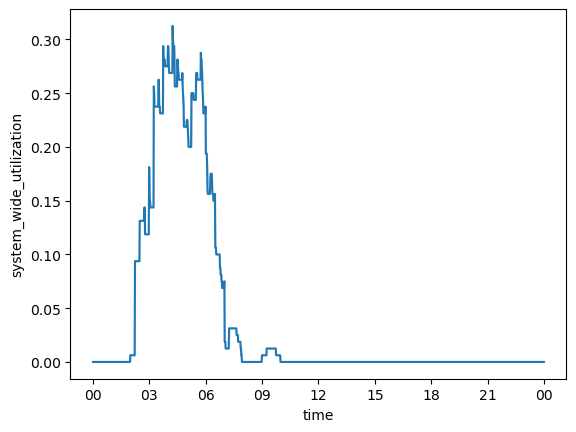

In [20]:
g = sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization')

ax = g.axes

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

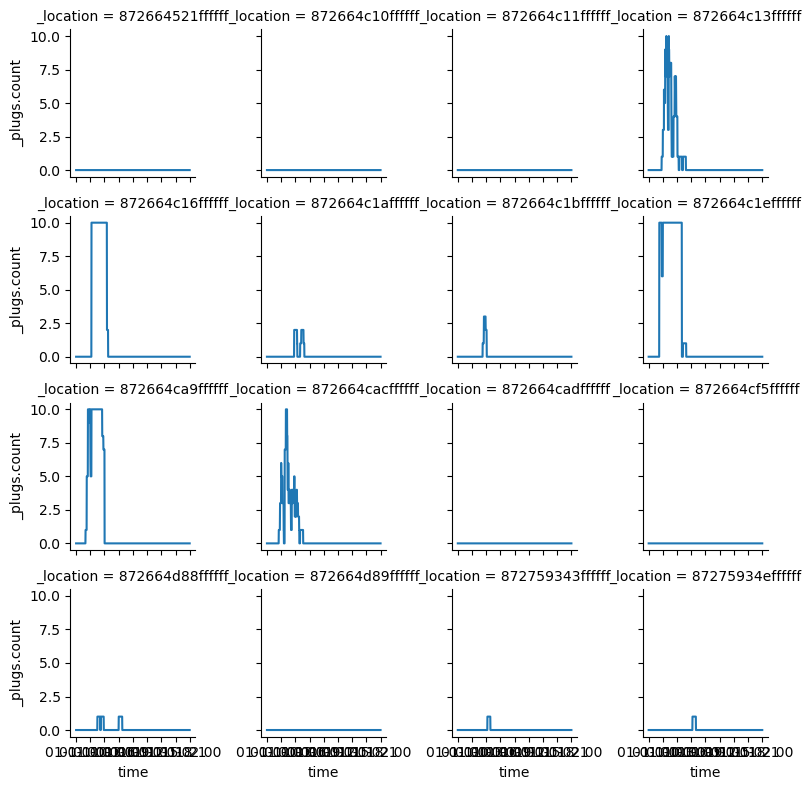

In [21]:
charging_station_tracking.sort_values(by=['time', '_location'], inplace=True)
sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4, height=2)

## Transactions

In [55]:
transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_transactions.csv")

In [66]:
RESAMPLE_RATE = '1h'

In [67]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'], format="%H:%M:%S")
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'], format="%H:%M:%S")
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [68]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")

transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")

Text(0.5, 1.0, 'Fleet 1')

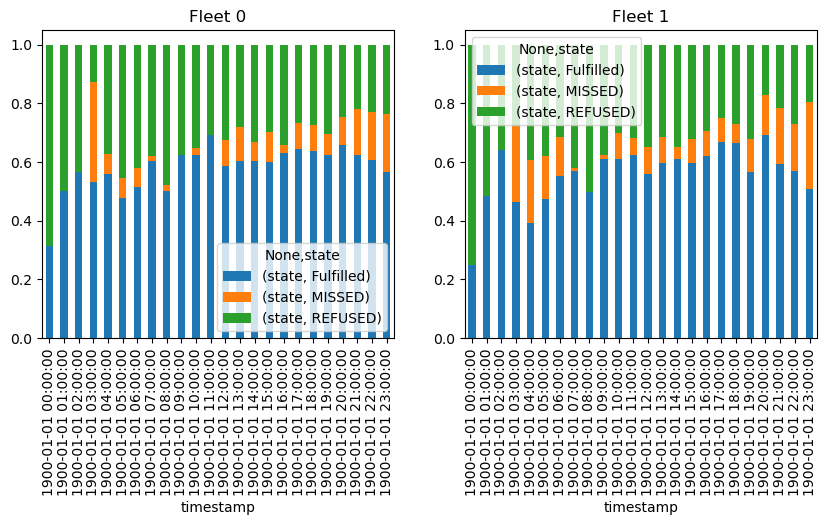

In [69]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0])
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1])

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

(0.0, 1.0)

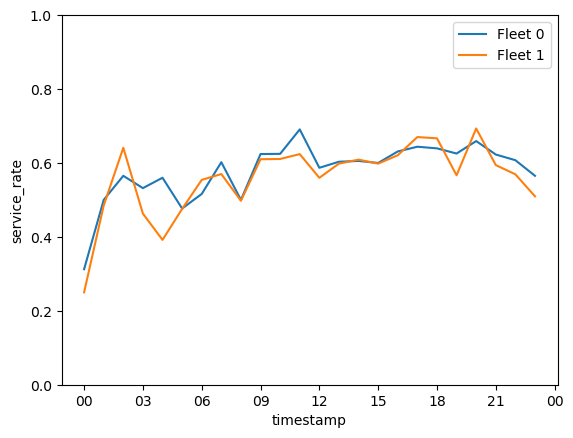

In [70]:
transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0')
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1')

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [96]:
vehicle_tracking['fleet_vdt'] = vehicle_tracking['_vdt'].apply(lambda x: sum(eval(x)))

In [97]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [98]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

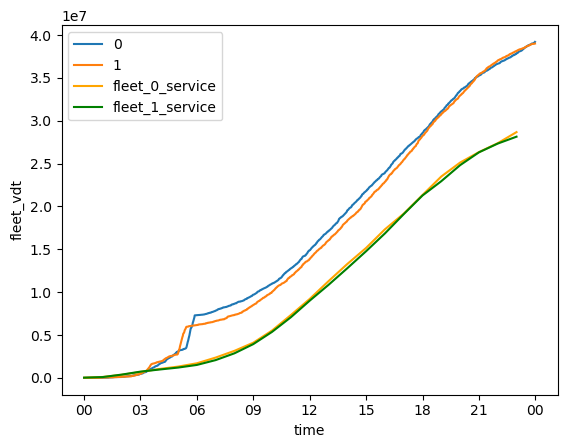

In [99]:
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_vdt', hue='_fleet')
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service')
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service')

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [107]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [108]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [111]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [114]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [115]:
hourly_vdt

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
1900-01-01 00:00:00,2.276091e+04,3.528958e+04,1.877614e+04,1.877614e+04,2.933916e+04,2.933916e+04,0.175071,0.168617,2.276091e+04,3.528958e+04
1900-01-01 01:00:00,1.078486e+05,1.188919e+05,9.430334e+04,1.130795e+05,7.198624e+04,1.013254e+05,-0.108308,0.138944,8.508767e+04,8.360227e+04
1900-01-01 02:00:00,4.614878e+05,4.623063e+05,2.457593e+05,3.588388e+05,2.861873e+05,3.875127e+05,0.305056,0.166642,3.536392e+05,3.434144e+05
1900-01-01 03:00:00,1.573322e+06,1.883596e+06,3.369308e+05,6.957696e+05,3.463276e+05,7.338403e+05,0.696959,0.756329,1.111834e+06,1.421290e+06
1900-01-01 04:00:00,3.073569e+06,2.790988e+06,3.473417e+05,1.043111e+06,2.441490e+05,9.779893e+05,0.768477,0.730933,1.500247e+06,9.073917e+05
1900-01-01 05:00:00,7.324405e+06,6.166334e+06,2.777862e+05,1.320898e+06,2.291648e+05,1.207154e+06,0.934651,0.932106,4.250836e+06,3.375346e+06
1900-01-01 06:00:00,7.834872e+06,6.633866e+06,3.868929e+05,1.707790e+06,3.090662e+05,1.516220e+06,0.242081,0.338942,5.104672e+05,4.675326e+05
1900-01-01 07:00:00,8.637573e+06,7.326700e+06,6.670316e+05,2.374822e+06,5.641540e+05,2.080374e+06,0.169016,0.185730,8.027008e+05,6.928339e+05
1900-01-01 08:00:00,9.696317e+06,8.488926e+06,7.872465e+05,3.162068e+06,7.935626e+05,2.873937e+06,0.256434,0.317205,1.058744e+06,1.162226e+06


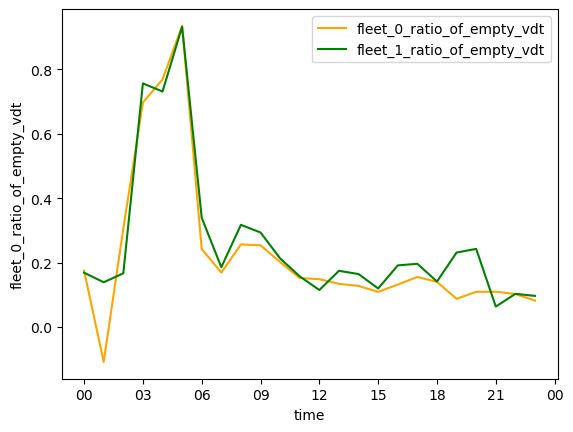

In [116]:
sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', color='orange', label='fleet_0_ratio_of_empty_vdt')
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', color='green', label='fleet_1_ratio_of_empty_vdt')

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [99]:
task_transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_task_transactions.csv")

In [102]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'], format="%H:%M:%S")

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'], format="%H:%M:%S")

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [103]:
task_transactions_fleet_0

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,106,145.966346,6,TaskState.FINISHED,0,872664ca9ffffff,7.132854,33.099201,27.582667,1900-01-01 01:46:00,39.966346
1,120,152.700020,162,TaskState.FINISHED,0,872664ca9ffffff,13.311777,31.011797,25.843164,1900-01-01 02:00:00,32.700020
2,113,159.740067,2,TaskState.FINISHED,0,872664ca9ffffff,8.724503,33.464570,27.887142,1900-01-01 01:53:00,46.740067
3,120,167.260644,246,TaskState.FINISHED,0,872664ca9ffffff,13.443646,30.704290,25.586909,1900-01-01 02:00:00,47.260644
4,120,169.048980,256,TaskState.FINISHED,0,872664ca9ffffff,11.999988,31.048968,25.874140,1900-01-01 02:00:00,49.048980
...,...,...,...,...,...,...,...,...,...,...,...
495,390,463.020730,292,TaskState.FINISHED,0,872664cacffffff,10.157348,38.178078,31.815065,1900-01-01 06:30:00,73.020730
496,360,463.088301,406,TaskState.FINISHED,0,872664d88ffffff,10.687522,38.775823,32.313186,1900-01-01 06:00:00,103.088301
497,441,509.846873,233,TaskState.FINISHED,0,872664cacffffff,12.369711,42.216584,35.180487,1900-01-01 07:21:00,68.846873
498,496,544.739153,352,TaskState.FINISHED,0,872759343ffffff,8.068503,42.807656,35.673047,1900-01-01 08:16:00,48.739153


In [104]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state             
TaskState.FINISHED    500
Name: count, dtype: int64

state             
TaskState.FINISHED    500
Name: count, dtype: int64

<Axes: xlabel='charging_duration', ylabel='kWh_charged'>

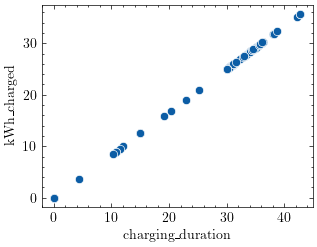

In [105]:
# check linearity
sns.scatterplot(data=task_transactions_fleet_0, x='charging_duration', y='kWh_charged')

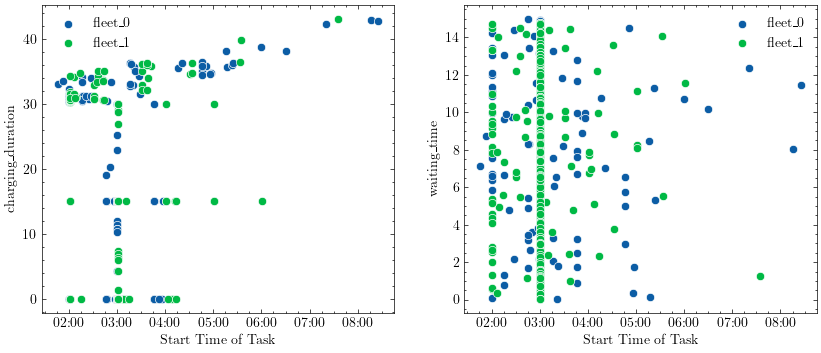

In [158]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1])

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [107]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

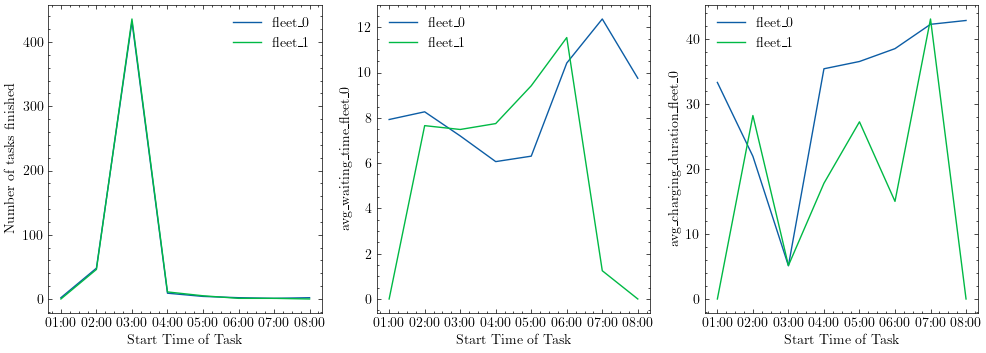

In [159]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [154]:
date_range = range(0,1440,15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [155]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_time)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'], format="%H:%M:%S")

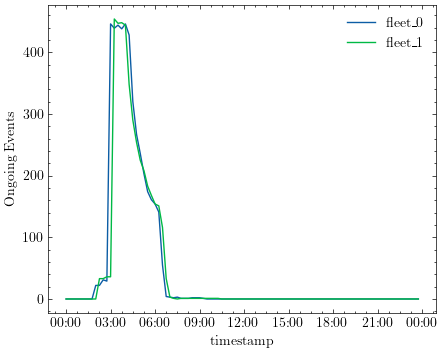

In [157]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))


### other stuff

<Axes: xlabel='waiting_time', ylabel='pick_up_time'>

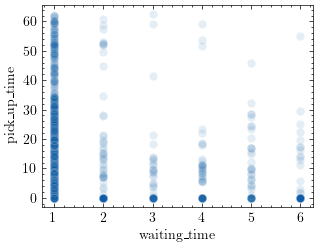

In [60]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [61]:
transactions_fleet_0['pick_up_time'].describe()

count    6618.000000
mean        5.894817
std         9.480927
min         0.000000
25%         0.000000
50%         2.184639
75%         7.826564
max        62.504271
Name: pick_up_time, dtype: float64